In [1]:
from pathlib import Path
import sys
import numpy as np

In [2]:

from pathlib import Path
import sys
import numpy as np

# Mencari folder utama proyek BAJANG TACTIC
current_path = Path.cwd().resolve()
project_path = None

for path in [current_path, *current_path.parents]:
    if (path / "official-repository").exists() and (path / "src").exists():
        project_path = path
        break

if project_path is None:
    raise FileNotFoundError("Folder BAJANG TACTIC tidak ditemukan.")

# Mendaftarkan folder utama proyek ke Python import path
if str(project_path) not in sys.path:
    sys.path.insert(0, str(project_path))

# Menentukan lokasi dataset
data_path = (
    project_path
    / "official-repository"
    / "more-than-a-hack-2027"
    / "data"
    / "tactical"
)

atd_path = data_path / "BAR-ATH_tactical_atd.txt"
metadata_path = data_path / "BAR-ATH_tactical_atd.xml"

print("Project:", project_path)
print("Folder src tersedia:", (project_path / "src").exists())
print("Dataset tersedia:", atd_path.exists())


FileNotFoundError: Folder BAJANG TACTIC tidak ditemukan.

In [ ]:
import numpy as np
from src.data_loader import iter_tracking
from src.feature_engineering import calculate_player_ball_distances

# Membaca beberapa frame pertama
tracking_iterator = iter_tracking(atd_path)

records = []

for _ in range(5):
    records.append(next(tracking_iterator))

print("Jumlah frame yang dibaca:", len(records))


Jumlah frame yang dibaca: 5


In [ ]:
# Menghitung jarak pemain ke bola pada frame pertama
distances = calculate_player_ball_distances(records[0])

# Menghitung jumlah pemain yang memiliki jarak valid
valid_distances = distances[np.isfinite(distances)]

print("Jumlah track slot:", len(distances))
print("Jumlah jarak valid:", len(valid_distances))
print("Jumlah jarak tidak tersedia:", np.isnan(distances).sum())

if len(valid_distances) > 0:
    print("Jarak minimum:", valid_distances.min())
    print("Jarak maksimum:", valid_distances.max())


Jumlah track slot: 46
Jumlah jarak valid: 0
Jumlah jarak tidak tersedia: 46


In [ ]:

# Mencari frame yang bola tidak terdeteksi
missing_ball_record = next(
    record for record in records
    if record["ball"] is None
)

missing_distances = calculate_player_ball_distances(
    missing_ball_record
)

print("Bola tersedia:", missing_ball_record["ball"] is not None)
print("Jumlah jarak valid:", np.isfinite(missing_distances).sum())
print("Jumlah jarak tidak tersedia:", np.isnan(missing_distances).sum())


Bola tersedia: False
Jumlah jarak valid: 0
Jumlah jarak tidak tersedia: 46


In [ ]:

for record in records:
    print(
        "Frame:", record["frame_id"],
        "| Bola tersedia:", record["ball"] is not None
    )


Frame: 1 | Bola tersedia: False
Frame: 2 | Bola tersedia: False
Frame: 3 | Bola tersedia: False
Frame: 4 | Bola tersedia: False
Frame: 5 | Bola tersedia: False


In [ ]:

# Membaca data sampai menemukan bola yang terdeteksi
tracking_iterator = iter_tracking(atd_path)

ball_detected_record = None

for record in tracking_iterator:

    if record["ball"] is not None:
        ball_detected_record = record
        break

if ball_detected_record is not None:
    print("Frame dengan bola terdeteksi:", ball_detected_record["frame_id"])
else:
    print("Tidak ditemukan frame dengan bola terdeteksi.")


Frame dengan bola terdeteksi: 4193


In [ ]:

if ball_detected_record is not None:

    distances = calculate_player_ball_distances(
        ball_detected_record
    )

    valid_distances = distances[np.isfinite(distances)]

    print("Jumlah track slot:", len(distances))
    print("Jumlah jarak valid:", len(valid_distances))
    print("Jumlah jarak tidak tersedia:", np.isnan(distances).sum())

    if len(valid_distances) > 0:
        print("Jarak minimum:", valid_distances.min())
        print("Jarak maksimum:", valid_distances.max())


Jumlah track slot: 46
Jumlah jarak valid: 13
Jumlah jarak tidak tersedia: 33
Jarak minimum: 5.706312617559259
Jarak maksimum: 51.75597184312164


In [ ]:
from src.data_loader import load_metadata

metadata = load_metadata(metadata_path)
team_mapping = metadata["team_mapping"]

In [ ]:

from src.feature_engineering import analyze_nearest_player

nearest_result = analyze_nearest_player(
    distances,
    team_mapping
)

print("Pemain terdekat (track slot):", nearest_result["nearest_player"])
print("Jarak terdekat:", nearest_result["nearest_distance"])
print("Tim terdekat:", nearest_result["nearest_team"])
print("Jumlah pemain Home:", nearest_result["home_players"])
print("Jumlah pemain Away:", nearest_result["away_players"])


Pemain terdekat (track slot): 29
Jarak terdekat: 5.706312617559259
Tim terdekat: 1
Jumlah pemain Home: 7
Jumlah pemain Away: 6


In [ ]:
from src.feature_engineering import calculate_player_ball_distances
from src.feature_engineering import analyze_nearest_player

# Hitung ulang jarak dalam meter
distances_meter = calculate_player_ball_distances(
    ball_detected_record
)

# Analisis pemain terdekat
nearest_result = analyze_nearest_player(
    distances_meter,
    team_mapping
)

print("Jumlah jarak valid:", np.sum(np.isfinite(distances_meter)))
print("Jarak minimum (meter):", np.nanmin(distances_meter))
print("Jarak maksimum (meter):", np.nanmax(distances_meter))

print("\nPemain terdekat:", nearest_result["nearest_player"])
print("Jarak terdekat (meter):", nearest_result["nearest_distance"])
print("Tim terdekat:", nearest_result["nearest_team"])

Jumlah jarak valid: 13
Jarak minimum (meter): 5.706312617559259
Jarak maksimum (meter): 51.75597184312164

Pemain terdekat: 29
Jarak terdekat (meter): 5.706312617559259
Tim terdekat: 1


In [ ]:
import inspect
from src.feature_engineering import calculate_player_ball_distances

print(inspect.getsource(calculate_player_ball_distances))

def calculate_player_ball_distances(
    record,
    pitch_length=105.3,
    pitch_width=68.0
):
    """
    Menghitung jarak setiap pemain ke bola dalam meter.

    Koordinat ATD dinormalisasi 0-1, sehingga:
    X dikalikan panjang lapangan.
    Y dikalikan lebar lapangan.

    Mengembalikan array jarak untuk setiap track slot.
    Nilai NaN berarti jarak tidak dapat dihitung.
    """
    players = record["players"]
    ball = record["ball"]

    distances = np.full(len(players), np.nan)

    if ball is None:
        return distances

    ball_x = ball["x"] * pitch_length
    ball_y = ball["y"] * pitch_width

    if not np.isfinite(ball_x) or not np.isfinite(ball_y):
        return distances

    for index, player in enumerate(players):
        if player is None:
            continue

        player_x = player["x"] * pitch_length
        player_y = player["y"] * pitch_width

        if not np.isfinite(player_x) or not np.isfinite(player_y):
            continue

        dx = player_x 

In [ ]:
distances_meter = calculate_player_ball_distances(ball_detected_record)

nearest_result = analyze_nearest_player(
    distances_meter,
    team_mapping
)

print("Jarak minimum (meter):", np.nanmin(distances_meter))
print("Jarak maksimum (meter):", np.nanmax(distances_meter))
print("Pemain terdekat:", nearest_result["nearest_player"])
print("Jarak terdekat (meter):", nearest_result["nearest_distance"])
print("Tim terdekat:", nearest_result["nearest_team"])

Jarak minimum (meter): 5.706312617559259
Jarak maksimum (meter): 51.75597184312164
Pemain terdekat: 29
Jarak terdekat (meter): 5.706312617559259
Tim terdekat: 1


In [ ]:
import importlib
import src.feature_engineering

importlib.reload(src.feature_engineering)

from src.feature_engineering import calculate_team_ball_distances

In [ ]:
team_distances = calculate_team_ball_distances(
    distances_meter,
    team_mapping
)

print("Jarak minimum Home (meter):",
      team_distances["home_min_distance"])

print("Jarak minimum Away (meter):",
      team_distances["away_min_distance"])

print("Selisih jarak kedua tim (meter):",
      team_distances["distance_difference"])

Jarak minimum Home (meter): 7.676908673979707
Jarak minimum Away (meter): 5.706312617559259
Selisih jarak kedua tim (meter): 1.9705960564204474


In [ ]:
import importlib
import src.feature_engineering

importlib.reload(src.feature_engineering)

from src.feature_engineering import count_players_near_ball

In [ ]:
near_ball_counts = count_players_near_ball(
    distances_meter,
    team_mapping,
    radii=(5, 10)
)

for radius, result in near_ball_counts.items():
    print(f"\nRadius {radius} meter")
    print("Pemain Home:", result["home_count"])
    print("Pemain Away:", result["away_count"])
    print("Total pemain:", result["total_count"])


Radius 5 meter
Pemain Home: 0
Pemain Away: 0
Total pemain: 0

Radius 10 meter
Pemain Home: 2
Pemain Away: 1
Total pemain: 3


In [ ]:

from src.data_loader import iter_tracking
import numpy as np

player_speeds = []
ball_speeds = []

player_speed_missing = 0
ball_speed_missing = 0
ball_not_detected = 0

for record in iter_tracking(atd_path):

    # Mengambil satu dari setiap 10 frame
    if (record["frame_id"] - 1) % 10 != 0:
        continue

    # Mengumpulkan kecepatan pemain
    for player in record["players"]:
        if player is None:
            player_speed_missing += 1
            continue

        speed = player["speed"]

        if np.isfinite(speed):
            player_speeds.append(speed)
        else:
            player_speed_missing += 1

    # Mengumpulkan kecepatan bola
    ball = record["ball"]

    if ball is None:
        ball_not_detected += 1
        continue

    if np.isfinite(ball["speed"]):
        ball_speeds.append(ball["speed"])
    else:
        ball_speed_missing += 1


player_speeds = np.array(player_speeds)
ball_speeds = np.array(ball_speeds)

print("Jumlah sampel kecepatan pemain:", len(player_speeds))
print("Jumlah sampel kecepatan bola:", len(ball_speeds))

print("\nKecepatan pemain yang tidak tersedia:", player_speed_missing)
print("Kecepatan bola tidak tersedia:", ball_speed_missing)
print("Bola tidak terdeteksi:", ball_not_detected)


def print_speed_statistics(name, speeds):
    if len(speeds) == 0:
        print(f"\nTidak ada data kecepatan {name}.")
        return

    percentiles = np.percentile(
        speeds, [0, 25, 50, 75, 90, 95, 99, 100]
    )

    print(f"\nStatistik kecepatan {name} (m/s)")
    print("Minimum:", percentiles[0])
    print("Q1:", percentiles[1])
    print("Median:", percentiles[2])
    print("Q3:", percentiles[3])
    print("P90:", percentiles[4])
    print("P95:", percentiles[5])
    print("P99:", percentiles[6])
    print("Maksimum:", percentiles[7])


print_speed_statistics("pemain", player_speeds)
print_speed_statistics("bola", ball_speeds)


Jumlah sampel kecepatan pemain: 341175
Jumlah sampel kecepatan bola: 994

Kecepatan pemain yang tidak tersedia: 575697
Kecepatan bola tidak tersedia: 10350
Bola tidak terdeteksi: 8588

Statistik kecepatan pemain (m/s)
Minimum: 0.0012473759707063437
Q1: 0.7749291956424713
Median: 1.3351701498031616
Q3: 2.311267614364624
P90: 3.7138136863708495
P95: 4.539307928085326
P99: 6.379524908065799
Maksimum: 11.29382610321045

Statistik kecepatan bola (m/s)
Minimum: 0.004234815016388893
Q1: 0.6938000917434692
Median: 1.2161583304405212
Q3: 1.774647444486618
P90: 3.3612903118133546
P95: 4.067557382583618
P99: 5.775540380477904
Maksimum: 7.129091739654541


In [ ]:

from src.data_loader import iter_tracking
from src.data_loader import load_metadata
import numpy as np

# Memastikan mapping tim tersedia
metadata = load_metadata(metadata_path)
team_mapping = metadata["team_mapping"]

# Menampung kecepatan berdasarkan tim
home_speeds = []
away_speeds = []

# Menghitung ketersediaan data
home_detected = 0
away_detected = 0

home_speed_missing = 0
away_speed_missing = 0

for record in iter_tracking(atd_path):

    # Sampling setiap 10 frame
    if (record["frame_id"] - 1) % 10 != 0:
        continue

    for index, player in enumerate(record["players"]):

        team = team_mapping[index]

        if player is None:
            continue

        speed = player["speed"]

        if team == 0:
            home_detected += 1

            if np.isfinite(speed):
                home_speeds.append(speed)
            else:
                home_speed_missing += 1

        else:
            away_detected += 1

            if np.isfinite(speed):
                away_speeds.append(speed)
            else:
                away_speed_missing += 1


home_speeds = np.array(home_speeds)
away_speeds = np.array(away_speeds)


def print_team_speed_statistics(team_name, speeds):
    if len(speeds) == 0:
        print(f"\nTidak ada data kecepatan {team_name}.")
        return

    percentiles = np.percentile(
        speeds, [0, 25, 50, 75, 90, 95, 99, 100]
    )

    print(f"\nStatistik kecepatan {team_name} (m/s)")
    print("Jumlah data valid:", len(speeds))
    print("Minimum:", percentiles[0])
    print("Q1:", percentiles[1])
    print("Median:", percentiles[2])
    print("Q3:", percentiles[3])
    print("P90:", percentiles[4])
    print("P95:", percentiles[5])
    print("P99:", percentiles[6])
    print("Maksimum:", percentiles[7])


print("=== KETERSEDIAAN DATA ===")

print("\nHOME (Barcelona)")
print("Pemain terdeteksi:", home_detected)
print("Kecepatan valid:", len(home_speeds))
print("Kecepatan tidak valid:", home_speed_missing)

print("\nAWAY (Athletic Club)")
print("Pemain terdeteksi:", away_detected)
print("Kecepatan valid:", len(away_speeds))
print("Kecepatan tidak valid:", away_speed_missing)

print_team_speed_statistics("Home", home_speeds)
print_team_speed_statistics("Away", away_speeds)


=== KETERSEDIAAN DATA ===

HOME (Barcelona)
Pemain terdeteksi: 192522
Kecepatan valid: 172104
Kecepatan tidak valid: 20418

AWAY (Athletic Club)
Pemain terdeteksi: 185751
Kecepatan valid: 169071
Kecepatan tidak valid: 16680

Statistik kecepatan Home (m/s)
Jumlah data valid: 172104
Minimum: 0.001508443965576589
Q1: 0.7634768486022949
Median: 1.3441871404647827
Q3: 2.322578549385071
P90: 3.723763155937195
P95: 4.540690135955811
P99: 6.448813037872315
Maksimum: 11.29382610321045

Statistik kecepatan Away (m/s)
Jumlah data valid: 169071
Minimum: 0.0012473759707063437
Q1: 0.7876915633678436
Median: 1.3269143104553223
Q3: 2.298974394798279
P90: 3.702439069747925
P95: 4.53729510307312
P99: 6.299165725708007
Maksimum: 9.401451110839844


In [ ]:
import importlib
import src.feature_engineering

importlib.reload(src.feature_engineering)

from src.feature_engineering import calculate_team_speed_features

speed_features = calculate_team_speed_features(
    ball_detected_record,
    team_mapping
)

print("Median kecepatan Home:",
      speed_features["home_median_speed"])

print("Median kecepatan Away:",
      speed_features["away_median_speed"])

print("Jumlah kecepatan valid Home:",
      speed_features["home_valid_speed_count"])

print("Jumlah kecepatan valid Away:",
      speed_features["away_valid_speed_count"])

Median kecepatan Home: 0.37868811190128326
Median kecepatan Away: 0.08976107090711594
Jumlah kecepatan valid Home: 4
Jumlah kecepatan valid Away: 5


In [ ]:

from src.data_loader import iter_tracking
from src.feature_engineering import calculate_team_speed_features
import numpy as np

home_frame_medians = []
away_frame_medians = []

sampled_frames = 0

for record in iter_tracking(atd_path):

    # Sampling setiap 100 frame
    if (record["frame_id"] - 1) % 100 != 0:
        continue

    features = calculate_team_speed_features(
        record,
        team_mapping
    )

    if np.isfinite(features["home_median_speed"]):
        home_frame_medians.append(
            features["home_median_speed"]
        )

    if np.isfinite(features["away_median_speed"]):
        away_frame_medians.append(
            features["away_median_speed"]
        )

    sampled_frames += 1

home_frame_medians = np.array(home_frame_medians)
away_frame_medians = np.array(away_frame_medians)

print("Jumlah frame sampel:", sampled_frames)

print("\nHOME")
print("Frame dengan data:", len(home_frame_medians))
print("Median kecepatan antar-frame:",
      np.median(home_frame_medians))
print("Rata-rata kecepatan antar-frame:",
      np.mean(home_frame_medians))

print("\nAWAY")
print("Frame dengan data:", len(away_frame_medians))
print("Median kecepatan antar-frame:",
      np.median(away_frame_medians))
print("Rata-rata kecepatan antar-frame:",
      np.mean(away_frame_medians))


Jumlah frame sampel: 1994

HOME
Frame dengan data: 1920
Median kecepatan antar-frame: 1.2716140747070312
Rata-rata kecepatan antar-frame: 1.5117518446820517

AWAY
Frame dengan data: 1925
Median kecepatan antar-frame: 1.2541730403900146
Rata-rata kecepatan antar-frame: 1.5027944275896463


In [ ]:

from src.data_loader import iter_tracking
import numpy as np

# Dimensi lapangan dalam meter
PITCH_LENGTH = 105.3
PITCH_WIDTH = 68.0

# Frekuensi video
FPS = 25

previous_record = None

ball_displacements = []
ball_derived_speeds = []

total_pairs = 0
valid_pairs = 0
missing_ball_pairs = 0
nonconsecutive_pairs = 0

for record in iter_tracking(atd_path):

    if previous_record is not None:

        previous_frame = previous_record["frame_id"]
        current_frame = record["frame_id"]

        total_pairs += 1

        # Pastikan kedua frame berurutan
        if current_frame != previous_frame + 1:
            nonconsecutive_pairs += 1
            previous_record = record
            continue

        previous_ball = previous_record["ball"]
        current_ball = record["ball"]

        # Kedua frame harus memiliki koordinat bola
        if previous_ball is None or current_ball is None:
            missing_ball_pairs += 1
            previous_record = record
            continue

        x1 = previous_ball["x"] * PITCH_LENGTH
        y1 = previous_ball["y"] * PITCH_WIDTH

        x2 = current_ball["x"] * PITCH_LENGTH
        y2 = current_ball["y"] * PITCH_WIDTH

        coordinates = [x1, y1, x2, y2]

        if not np.all(np.isfinite(coordinates)):
            previous_record = record
            continue

        dx = x2 - x1
        dy = y2 - y1

        displacement = np.sqrt(dx**2 + dy**2)
        derived_speed = displacement * FPS

        ball_displacements.append(displacement)
        ball_derived_speeds.append(derived_speed)

        valid_pairs += 1

    previous_record = record


ball_displacements = np.array(ball_displacements)
ball_derived_speeds = np.array(ball_derived_speeds)

print("=== KETERSEDIAAN PASANGAN FRAME ===")
print("Total pasangan frame:", total_pairs)
print("Pasangan dengan bola valid:", valid_pairs)
print("Pasangan dengan bola tidak tersedia:", missing_ball_pairs)
print("Pasangan frame tidak berurutan:", nonconsecutive_pairs)

print("\n=== STATISTIK PERPINDAHAN BOLA ===")

if len(ball_displacements) > 0:

    print("Jumlah data:", len(ball_displacements))
    print("Median perpindahan (meter):",
          np.median(ball_displacements))
    print("P95 perpindahan (meter):",
          np.percentile(ball_displacements, 95))
    print("Maksimum perpindahan (meter):",
          np.max(ball_displacements))

    print("\n=== KECEPATAN BOLA HASIL PERHITUNGAN ===")

    print("Median (m/s):",
          np.median(ball_derived_speeds))
    print("P90 (m/s):",
          np.percentile(ball_derived_speeds, 90))
    print("P95 (m/s):",
          np.percentile(ball_derived_speeds, 95))
    print("P99 (m/s):",
          np.percentile(ball_derived_speeds, 99))
    print("Maksimum (m/s):",
          np.max(ball_derived_speeds))


=== KETERSEDIAAN PASANGAN FRAME ===
Total pasangan frame: 199318
Pasangan dengan bola valid: 113303
Pasangan dengan bola tidak tersedia: 86015
Pasangan frame tidak berurutan: 0

=== STATISTIK PERPINDAHAN BOLA ===
Jumlah data: 113303
Median perpindahan (meter): 0.2216188779052874
P95 perpindahan (meter): 0.9520822163764436
Maksimum perpindahan (meter): 5.35942047409242

=== KECEPATAN BOLA HASIL PERHITUNGAN ===
Median (m/s): 5.540471947632184
P90 (m/s): 17.228504151477793
P95 (m/s): 23.80205540941109
P99 (m/s): 50.326257741321086
Maksimum (m/s): 133.98551185231048


In [ ]:

from src.data_loader import iter_tracking
import numpy as np

FPS = 25
PITCH_LENGTH = 105.3
PITCH_WIDTH = 68.0

previous_record = None

derived_speeds = []
atd_speeds = []

for record in iter_tracking(atd_path):

    if previous_record is not None:

        if record["frame_id"] != previous_record["frame_id"] + 1:
            previous_record = record
            continue

        previous_ball = previous_record["ball"]
        current_ball = record["ball"]

        if previous_ball is None or current_ball is None:
            previous_record = record
            continue

        if not np.isfinite(current_ball["speed"]):
            previous_record = record
            continue

        x1 = previous_ball["x"] * PITCH_LENGTH
        y1 = previous_ball["y"] * PITCH_WIDTH

        x2 = current_ball["x"] * PITCH_LENGTH
        y2 = current_ball["y"] * PITCH_WIDTH

        coordinates = [x1, y1, x2, y2]

        if not np.all(np.isfinite(coordinates)):
            previous_record = record
            continue

        displacement = np.sqrt(
            (x2 - x1)**2 + (y2 - y1)**2
        )

        derived_speed = displacement * FPS

        derived_speeds.append(derived_speed)
        atd_speeds.append(current_ball["speed"])

    previous_record = record


derived_speeds = np.array(derived_speeds)
atd_speeds = np.array(atd_speeds)

print("Jumlah pasangan untuk perbandingan:", len(derived_speeds))

print("\nKecepatan hasil perhitungan (m/s)")
print("Median:", np.median(derived_speeds))
print("P90:", np.percentile(derived_speeds, 90))
print("P95:", np.percentile(derived_speeds, 95))
print("P99:", np.percentile(derived_speeds, 99))

print("\nKecepatan bawaan ATD (m/s)")
print("Median:", np.median(atd_speeds))
print("P90:", np.percentile(atd_speeds, 90))
print("P95:", np.percentile(atd_speeds, 95))
print("P99:", np.percentile(atd_speeds, 99))

print("\nKorelasi Pearson:")
if len(derived_speeds) > 1:
    print(np.corrcoef(derived_speeds, atd_speeds)[0, 1])


Jumlah pasangan untuk perbandingan: 9889

Kecepatan hasil perhitungan (m/s)
Median: 5.937588167766177
P90: 20.061001088760186
P95: 30.06095527551606
P99: 53.24709355620342

Kecepatan bawaan ATD (m/s)
Median: 1.209194540977478
P90: 3.3869089126586935
P95: 4.073659992218018
P99: 5.75234186172487

Korelasi Pearson:
-0.09746875711231177


In [ ]:

import numpy as np

thresholds = [1, 2, 3]

total = len(ball_displacements)

print("Total perpindahan valid:", total)

print("\n=== ANALISIS LONJAKAN KOORDINAT BOLA ===")

for threshold in thresholds:

    spike_count = np.sum(ball_displacements > threshold)

    percentage = (
        spike_count / total * 100
        if total > 0 else 0
    )

    print(f"\nPerpindahan > {threshold} meter/frame")
    print("Jumlah kejadian:", spike_count)
    print("Persentase:", round(percentage, 4), "%")


print("\n=== DISTRIBUSI PERPINDAHAN ===")

percentiles = [50, 75, 90, 95, 99, 99.5, 99.9, 100]

for percentile in percentiles:

    value = np.percentile(
        ball_displacements,
        percentile
    )

    print(f"P{percentile}: {value:.4f} meter/frame")


Total perpindahan valid: 113303

=== ANALISIS LONJAKAN KOORDINAT BOLA ===

Perpindahan > 1 meter/frame
Jumlah kejadian: 5159
Persentase: 4.5533 %

Perpindahan > 2 meter/frame
Jumlah kejadian: 1158
Persentase: 1.022 %

Perpindahan > 3 meter/frame
Jumlah kejadian: 181
Persentase: 0.1597 %

=== DISTRIBUSI PERPINDAHAN ===
P50: 0.2216 meter/frame
P75: 0.4325 meter/frame
P90: 0.6891 meter/frame
P95: 0.9521 meter/frame
P99: 2.0131 meter/frame
P99.5: 2.4125 meter/frame
P99.9: 3.3862 meter/frame
P100: 5.3594 meter/frame


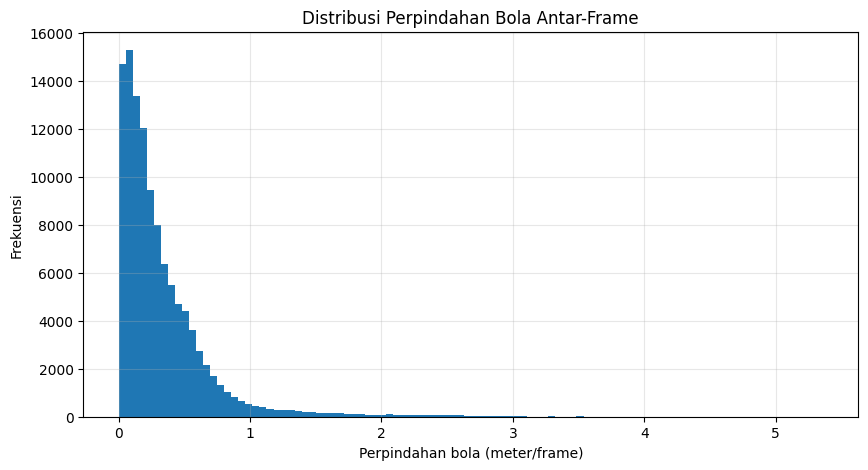

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    ball_displacements,
    bins=100
)

plt.xlabel("Perpindahan bola (meter/frame)")
plt.ylabel("Frekuensi")
plt.title("Distribusi Perpindahan Bola Antar-Frame")
plt.grid(alpha=0.3)

plt.show()


In [ ]:

from src.data_loader import iter_tracking
import numpy as np

previous_record = None
large_jumps = []

for record in iter_tracking(atd_path):

    if previous_record is not None:

        if record["frame_id"] != previous_record["frame_id"] + 1:
            previous_record = record
            continue

        previous_ball = previous_record["ball"]
        current_ball = record["ball"]

        if previous_ball is None or current_ball is None:
            previous_record = record
            continue

        x1 = previous_ball["x"] * 105.3
        y1 = previous_ball["y"] * 68.0

        x2 = current_ball["x"] * 105.3
        y2 = current_ball["y"] * 68.0

        displacement = np.sqrt(
            (x2 - x1)**2 + (y2 - y1)**2
        )

        if displacement > 1.0:
            large_jumps.append({
                "previous_frame": previous_record["frame_id"],
                "current_frame": record["frame_id"],
                "displacement": displacement,
                "derived_speed": displacement * 25,
                "atd_speed": current_ball["speed"],
                "previous_x": previous_ball["x"],
                "previous_y": previous_ball["y"],
                "current_x": current_ball["x"],
                "current_y": current_ball["y"]
            })

    previous_record = record


# Urutkan berdasarkan perpindahan terbesar
large_jumps.sort(
    key=lambda item: item["displacement"],
    reverse=True
)

print("Jumlah lonjakan:", len(large_jumps))
print("\n20 LONJAKAN TERBESAR\n")

for item in large_jumps[:20]:
    print(
        f"Frame {item['previous_frame']} -> "
        f"{item['current_frame']} | "
        f"Perpindahan: {item['displacement']:.3f} m | "
        f"Kecepatan hitung: {item['derived_speed']:.2f} m/s | "
        f"Kecepatan ATD: {item['atd_speed']}"
    )


Jumlah lonjakan: 5159

20 LONJAKAN TERBESAR

Frame 106716 -> 106717 | Perpindahan: 5.359 m | Kecepatan hitung: 133.99 m/s | Kecepatan ATD: 0.6000880002975464
Frame 106717 -> 106718 | Perpindahan: 5.259 m | Kecepatan hitung: 131.48 m/s | Kecepatan ATD: 0.6951352953910828
Frame 106718 -> 106719 | Perpindahan: 5.097 m | Kecepatan hitung: 127.43 m/s | Kecepatan ATD: 0.7930394411087036
Frame 106719 -> 106720 | Perpindahan: 4.878 m | Kecepatan hitung: 121.95 m/s | Kecepatan ATD: 0.8905163407325745
Frame 108966 -> 108967 | Perpindahan: 4.614 m | Kecepatan hitung: 115.35 m/s | Kecepatan ATD: nan
Frame 108965 -> 108966 | Perpindahan: 4.611 m | Kecepatan hitung: 115.28 m/s | Kecepatan ATD: nan
Frame 106720 -> 106721 | Perpindahan: 4.602 m | Kecepatan hitung: 115.04 m/s | Kecepatan ATD: 0.9844709038734436
Frame 108967 -> 108968 | Perpindahan: 4.582 m | Kecepatan hitung: 114.54 m/s | Kecepatan ATD: nan
Frame 108964 -> 108965 | Perpindahan: 4.572 m | Kecepatan hitung: 114.30 m/s | Kecepatan ATD: na

In [ ]:

from src.data_loader import iter_tracking
import numpy as np

# Rentang frame yang akan diperiksa
frame_ranges = [
    (106712, 106725),
    (108958, 108974)
]

selected_records = {}

for record in iter_tracking(atd_path):
    frame_id = record["frame_id"]

    for start, end in frame_ranges:
        if start <= frame_id <= end:
            selected_records[frame_id] = record
            break

for start, end in frame_ranges:

    print(f"\n=== FRAME {start} - {end} ===")

    previous_ball = None

    for frame_id in range(start, end + 1):

        record = selected_records.get(frame_id)

        if record is None:
            print(frame_id, "| Data frame tidak tersedia")
            previous_ball = None
            continue

        ball = record["ball"]

        if ball is None:
            print(frame_id, "| Bola tidak terdeteksi")
            previous_ball = None
            continue

        x = ball["x"]
        y = ball["y"]
        speed = ball["speed"]

        displacement = np.nan

        if previous_ball is not None:
            dx = (x - previous_ball["x"]) * 105.3
            dy = (y - previous_ball["y"]) * 68.0
            displacement = np.sqrt(dx**2 + dy**2)

        print(
            f"Frame: {frame_id} | "
            f"X: {x:.5f} | "
            f"Y: {y:.5f} | "
            f"ATD Speed: {speed} | "
            f"Perpindahan: {displacement:.3f} m"
            if np.isfinite(displacement)
            else
            f"Frame: {frame_id} | "
            f"X: {x:.5f} | "
            f"Y: {y:.5f} | "
            f"ATD Speed: {speed} | "
            "Perpindahan: -"
        )

        previous_ball = ball



=== FRAME 106712 - 106725 ===
106712 | Bola tidak terdeteksi
106713 | Bola tidak terdeteksi
106714 | Bola tidak terdeteksi
106715 | Bola tidak terdeteksi
Frame: 106716 | X: 0.77476 | Y: 0.41841 | ATD Speed: 0.5113254189491272 | Perpindahan: -
Frame: 106717 | X: 0.72963 | Y: 0.45485 | ATD Speed: 0.6000880002975464 | Perpindahan: 5.359 m
Frame: 106718 | X: 0.68532 | Y: 0.49054 | ATD Speed: 0.6951352953910828 | Perpindahan: 5.259 m
Frame: 106719 | X: 0.64234 | Y: 0.52503 | ATD Speed: 0.7930394411087036 | Perpindahan: 5.097 m
Frame: 106720 | X: 0.60117 | Y: 0.55791 | ATD Speed: 0.8905163407325745 | Perpindahan: 4.878 m
Frame: 106721 | X: 0.56228 | Y: 0.58878 | ATD Speed: 0.9844709038734436 | Perpindahan: 4.602 m
Frame: 106722 | X: 0.52608 | Y: 0.61730 | ATD Speed: 1.0720336437225342 | Perpindahan: 4.277 m
Frame: 106723 | X: 0.49292 | Y: 0.64314 | ATD Speed: 1.1505954265594482 | Perpindahan: 3.909 m
Frame: 106724 | X: 0.46312 | Y: 0.66604 | ATD Speed: 1.2178428173065186 | Perpindahan: 3.50

In [ ]:

from src.data_loader import iter_tracking
import numpy as np

frame_targets = [106716, 108966]

target_records = {}

for record in iter_tracking(atd_path):
    if record["frame_id"] in frame_targets:
        target_records[record["frame_id"]] = record

for frame_id in frame_targets:

    record = target_records.get(frame_id)

    if record is None:
        print("Frame tidak ditemukan:", frame_id)
        continue

    player_speeds = [
        player["speed"]
        for player in record["players"]
        if player is not None
        and np.isfinite(player["speed"])
    ]

    print(f"\n=== FRAME {frame_id} ===")
    print("Jumlah pemain dengan speed valid:", len(player_speeds))

    if player_speeds:
        print("Median speed pemain:",
              np.median(player_speeds))

        print("P90 speed pemain:",
              np.percentile(player_speeds, 90))

        print("Maksimum speed pemain:",
              np.max(player_speeds))

    print("Ball speed:", record["ball"]["speed"])



=== FRAME 106716 ===
Jumlah pemain dengan speed valid: 10
Median speed pemain: 0.3936985582113266
P90 speed pemain: 0.995750457048416
Maksimum speed pemain: 1.392095923423767
Ball speed: 0.5113254189491272

=== FRAME 108966 ===
Jumlah pemain dengan speed valid: 16
Median speed pemain: 0.7774625420570374
P90 speed pemain: 1.6514267325401306
Maksimum speed pemain: 3.6647891998291016
Ball speed: nan


In [ ]:

from src.data_loader import iter_tracking
from src.feature_engineering import calculate_player_ball_distances
from src.feature_engineering import analyze_nearest_player
import numpy as np

frame_ranges = [
    (106716, 106725),
    (108958, 108974)
]

for start, end in frame_ranges:

    print(f"\n=== FRAME {start} - {end} ===")

    for record in iter_tracking(atd_path):

        frame_id = record["frame_id"]

        if frame_id < start:
            continue

        if frame_id > end:
            break

        if record["ball"] is None:
            print(f"Frame {frame_id}: Bola tidak terdeteksi")
            continue

        distances = calculate_player_ball_distances(record)

        result = analyze_nearest_player(
            distances,
            team_mapping
        )

        if result["nearest_distance"] is None:
            print(f"Frame {frame_id}: Tidak ada pemain valid")
            continue

        print(
            f"Frame {frame_id} | "
            f"Jarak pemain terdekat: "
            f"{result['nearest_distance']:.2f} m | "
            f"Tim terdekat: "
            f"{'Home' if result['nearest_team'] == 0 else 'Away'}"
        )



=== FRAME 106716 - 106725 ===
Frame 106716 | Jarak pemain terdekat: 13.06 m | Tim terdekat: Away
Frame 106717 | Jarak pemain terdekat: 15.72 m | Tim terdekat: Away
Frame 106718 | Jarak pemain terdekat: 19.44 m | Tim terdekat: Away
Frame 106719 | Jarak pemain terdekat: 16.23 m | Tim terdekat: Away
Frame 106720 | Jarak pemain terdekat: 11.67 m | Tim terdekat: Away
Frame 106721 | Jarak pemain terdekat: 7.72 m | Tim terdekat: Away
Frame 106722 | Jarak pemain terdekat: 5.10 m | Tim terdekat: Away
Frame 106723 | Jarak pemain terdekat: 2.36 m | Tim terdekat: Home
Frame 106724 | Jarak pemain terdekat: 2.18 m | Tim terdekat: Home
Frame 106725 | Jarak pemain terdekat: 4.90 m | Tim terdekat: Home

=== FRAME 108958 - 108974 ===
Frame 108958 | Jarak pemain terdekat: 10.39 m | Tim terdekat: Home
Frame 108959 | Jarak pemain terdekat: 14.11 m | Tim terdekat: Home
Frame 108960 | Jarak pemain terdekat: 14.78 m | Tim terdekat: Home
Frame 108961 | Jarak pemain terdekat: 10.87 m | Tim terdekat: Home
Frame

In [ ]:

from src.data_loader import iter_tracking
from src.feature_engineering import calculate_player_ball_distances
import numpy as np

frame_ranges = [
    (106716, 106725),
    (108958, 108974)
]

for start, end in frame_ranges:

    print(f"\n=== FRAME {start} - {end} ===")

    for record in iter_tracking(atd_path):

        frame_id = record["frame_id"]

        if frame_id < start:
            continue

        if frame_id > end:
            break

        if record["ball"] is None:
            continue

        distances = calculate_player_ball_distances(record)
        valid_indices = np.where(np.isfinite(distances))[0]

        if len(valid_indices) == 0:
            continue

        nearest_index = valid_indices[
            np.argmin(distances[valid_indices])
        ]

        player = record["players"][nearest_index]
        ball = record["ball"]

        print(
            f"Frame: {frame_id} | "
            f"Track slot: {nearest_index} | "
            f"Tim: {'Home' if team_mapping[nearest_index] == 0 else 'Away'} | "
            f"Jarak: {distances[nearest_index]:.2f} m | "
            f"Player X: {player['x']:.5f} | "
            f"Player Y: {player['y']:.5f} | "
            f"Ball X: {ball['x']:.5f} | "
            f"Ball Y: {ball['y']:.5f}"
        )



=== FRAME 106716 - 106725 ===
Frame: 106716 | Track slot: 45 | Tim: Away | Jarak: 13.06 m | Player X: 0.86636 | Player Y: 0.54789 | Ball X: 0.77476 | Ball Y: 0.41841
Frame: 106717 | Track slot: 45 | Tim: Away | Jarak: 15.72 m | Player X: 0.86629 | Player Y: 0.54788 | Ball X: 0.72963 | Ball Y: 0.45485
Frame: 106718 | Track slot: 45 | Tim: Away | Jarak: 19.44 m | Player X: 0.86623 | Player Y: 0.54785 | Ball X: 0.68532 | Ball Y: 0.49054
Frame: 106719 | Track slot: 33 | Tim: Away | Jarak: 16.23 m | Player X: 0.49043 | Player Y: 0.56509 | Ball X: 0.64234 | Ball Y: 0.52503
Frame: 106720 | Track slot: 33 | Tim: Away | Jarak: 11.67 m | Player X: 0.49043 | Player Y: 0.56542 | Ball X: 0.60117 | Ball Y: 0.55791
Frame: 106721 | Track slot: 33 | Tim: Away | Jarak: 7.72 m | Player X: 0.49047 | Player Y: 0.56581 | Ball X: 0.56228 | Ball Y: 0.58878
Frame: 106722 | Track slot: 33 | Tim: Away | Jarak: 5.10 m | Player X: 0.49053 | Player Y: 0.56627 | Ball X: 0.52608 | Ball Y: 0.61730
Frame: 106723 | Tra

In [ ]:

import importlib
import src.feature_engineering as feature_engineering

# Memuat ulang modul agar fungsi terbaru terbaca
importlib.reload(feature_engineering)

# Menguji frame dengan bola terdeteksi
features_detected = feature_engineering.extract_frame_features(
    ball_detected_record,
    team_mapping
)

# Menguji frame tanpa bola
features_missing = feature_engineering.extract_frame_features(
    records[0],
    team_mapping
)

print("=== FRAME DENGAN BOLA ===")
for key, value in features_detected.items():
    print(f"{key}: {value}")

print("\n=== FRAME TANPA BOLA ===")
for key, value in features_missing.items():
    print(f"{key}: {value}")


=== FRAME DENGAN BOLA ===
frame_id: 4193
ball_detected: 1
nearest_player_distance: 5.706312617559259
nearest_player_team: 1
home_min_distance: 7.676908673979707
away_min_distance: 5.706312617559259
distance_difference: 1.9705960564204474
home_players_5m: 0
away_players_5m: 0
home_players_10m: 2
away_players_10m: 1
home_median_speed: 0.37868811190128326
away_median_speed: 0.08976107090711594
home_valid_speed_count: 4
away_valid_speed_count: 5

=== FRAME TANPA BOLA ===
frame_id: 1
ball_detected: 0
nearest_player_distance: nan
nearest_player_team: nan
home_min_distance: nan
away_min_distance: nan
distance_difference: nan
home_players_5m: nan
away_players_5m: nan
home_players_10m: nan
away_players_10m: nan
home_median_speed: 0.8868629932403564
away_median_speed: 1.2893087267875671
home_valid_speed_count: 1
away_valid_speed_count: 4


In [ ]:

import pandas as pd
from src.feature_engineering import extract_frame_features

feature_samples = []

for record in records:
    features = extract_frame_features(record, team_mapping)
    feature_samples.append(features)

features_df = pd.DataFrame(feature_samples)

print("Jumlah frame:", len(features_df))
print("Jumlah kolom fitur:", len(features_df.columns))

print("\nJumlah nilai kosong setiap fitur:")
print(features_df.isna().sum())

print("\nContoh hasil ekstraksi:")
display(features_df.head(10))


Jumlah frame: 5
Jumlah kolom fitur: 15

Jumlah nilai kosong setiap fitur:
frame_id                   0
ball_detected              0
nearest_player_distance    5
nearest_player_team        5
home_min_distance          5
away_min_distance          5
distance_difference        5
home_players_5m            5
away_players_5m            5
home_players_10m           5
away_players_10m           5
home_median_speed          0
away_median_speed          0
home_valid_speed_count     0
away_valid_speed_count     0
dtype: int64

Contoh hasil ekstraksi:


,frame_id,ball_detected,nearest_player_distance,nearest_player_team,home_min_distance,away_min_distance,distance_difference,home_players_5m,away_players_5m,home_players_10m,away_players_10m,home_median_speed,away_median_speed,home_valid_speed_count,away_valid_speed_count
0,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886863,1.289309,1,4
1,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886863,1.289309,1,4
2,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886863,1.289309,1,4
3,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886863,1.289309,1,4
4,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886863,1.289309,1,4


In [ ]:

from src.data_loader import iter_tracking
from src.feature_engineering import extract_frame_features
import pandas as pd

feature_samples = []

# Ambil maksimal 100 frame yang memiliki variasi kondisi
# Sampel diambil setiap 1000 frame
for record in iter_tracking(atd_path):
    if (record["frame_id"] - 1) % 1000 == 0:
        features = extract_frame_features(record, team_mapping)
        feature_samples.append(features)

features_df = pd.DataFrame(feature_samples)

print("Jumlah frame sampel:", len(features_df))
print("Jumlah kolom fitur:", len(features_df.columns))

print("\nDistribusi deteksi bola:")
print(features_df["ball_detected"].value_counts())

print("\nJumlah nilai kosong:")
print(features_df.isna().sum())

print("\nContoh frame dengan bola terdeteksi:")
display(
    features_df[features_df["ball_detected"] == 1].head(5)
)

print("\nContoh frame tanpa bola:")
display(
    features_df[features_df["ball_detected"] == 0].head(5)
)


Jumlah frame sampel: 200
Jumlah kolom fitur: 15

Distribusi deteksi bola:
ball_detected
1    123
0     77
Name: count, dtype: int64

Jumlah nilai kosong:
frame_id                    0
ball_detected               0
nearest_player_distance    77
nearest_player_team        77
home_min_distance          78
away_min_distance          77
distance_difference        78
home_players_5m            77
away_players_5m            77
home_players_10m           77
away_players_10m           77
home_median_speed          16
away_median_speed          14
home_valid_speed_count      0
away_valid_speed_count      0
dtype: int64

Contoh frame dengan bola terdeteksi:


,frame_id,ball_detected,nearest_player_distance,nearest_player_team,home_min_distance,away_min_distance,distance_difference,home_players_5m,away_players_5m,home_players_10m,away_players_10m,home_median_speed,away_median_speed,home_valid_speed_count,away_valid_speed_count
12,12001,1,7.174235,0.0,7.174235,8.812949,1.638715,0.0,0.0,2.0,1.0,0.971305,1.006068,10,10
13,13001,1,1.037962,0.0,1.037962,11.524527,10.486565,1.0,0.0,2.0,0.0,1.095189,1.067165,10,11
14,14001,1,2.832549,0.0,2.832549,5.334420,2.501871,2.0,0.0,2.0,2.0,2.184480,2.808401,10,11
15,15001,1,5.512062,0.0,5.512062,6.128186,0.616123,0.0,0.0,4.0,3.0,3.039436,2.018115,10,10
16,16001,1,7.506552,0.0,7.506552,33.722687,26.216135,0.0,0.0,1.0,0.0,1.448809,1.176711,11,8



Contoh frame tanpa bola:


,frame_id,ball_detected,nearest_player_distance,nearest_player_team,home_min_distance,away_min_distance,distance_difference,home_players_5m,away_players_5m,home_players_10m,away_players_10m,home_median_speed,away_median_speed,home_valid_speed_count,away_valid_speed_count
0,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886863,1.289309,1,4
1,1001,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.992290,0,5
2,2001,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.090554,0.077955,1,1
3,3001,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.022848,0.908643,1,5
4,4001,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.216841,0,2


In [ ]:

import csv
from pathlib import Path
from src.data_loader import iter_tracking
from src.feature_engineering import extract_frame_features

# Lokasi penyimpanan hasil
experiments_path = project_path / "experiments"
experiments_path.mkdir(parents=True, exist_ok=True)

output_path = experiments_path / "frame_features.csv"

# Penghitung proses
processed_frames = 0
ball_detected_count = 0
ball_missing_count = 0

print("Memulai ekstraksi fitur...")

with open(output_path, "w", newline="", encoding="utf-8") as file:

    writer = None

    for record in iter_tracking(atd_path):

        # Ekstraksi fitur satu frame
        features = extract_frame_features(
            record,
            team_mapping,
            pitch_length=105.3,
            pitch_width=68.0
        )

        # Buat header CSV berdasarkan fitur pertama
        if writer is None:
            writer = csv.DictWriter(
                file,
                fieldnames=list(features.keys())
            )
            writer.writeheader()

        # Simpan hasil langsung ke CSV
        writer.writerow(features)

        processed_frames += 1

        if features["ball_detected"] == 1:
            ball_detected_count += 1
        else:
            ball_missing_count += 1

        # Tampilkan progres setiap 25.000 frame
        if processed_frames % 25000 == 0:
            print(f"Frame diproses: {processed_frames:,}")

print("\nEkstraksi selesai.")
print("Total frame:", processed_frames)
print("Bola terdeteksi:", ball_detected_count)
print("Bola tidak terdeteksi:", ball_missing_count)
print("Lokasi file:", output_path)
print("Ukuran file (MB):", round(output_path.stat().st_size / (1024**2), 2))


Memulai ekstraksi fitur...
Frame diproses: 25,000
Frame diproses: 50,000
Frame diproses: 75,000
Frame diproses: 100,000
Frame diproses: 125,000
Frame diproses: 150,000
Frame diproses: 175,000

Ekstraksi selesai.
Total frame: 199319
Bola terdeteksi: 113488
Bola tidak terdeteksi: 85831
Lokasi file: D:\BAJANG TACTIC\experiments\frame_features.csv
Ukuran file (MB): 21.76


In [ ]:

# Periksa CSV tanpa memuat seluruh isinya ke RAM
with open(output_path, "r", newline="", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    columns = reader.fieldnames
    row_count = 0
    first_frame = None
    last_frame = None

    for row in reader:
        frame_id = int(row["frame_id"])

        if first_frame is None:
            first_frame = frame_id

        last_frame = frame_id
        row_count += 1

print("=== VERIFIKASI CSV ===")
print("Jumlah kolom:", len(columns))
print("Nama kolom:", columns)
print("Jumlah baris:", row_count)
print("Frame pertama:", first_frame)
print("Frame terakhir:", last_frame)

print("\nPemeriksaan:")
print("Jumlah frame benar:", row_count == 199319)
print("Frame pertama benar:", first_frame == 1)
print("Frame terakhir benar:", last_frame == 199319)
print("Jumlah kolom benar:", len(columns) == 15)

=== VERIFIKASI CSV ===
Jumlah kolom: 15
Nama kolom: ['frame_id', 'ball_detected', 'nearest_player_distance', 'nearest_player_team', 'home_min_distance', 'away_min_distance', 'distance_difference', 'home_players_5m', 'away_players_5m', 'home_players_10m', 'away_players_10m', 'home_median_speed', 'away_median_speed', 'home_valid_speed_count', 'away_valid_speed_count']
Jumlah baris: 199319
Frame pertama: 1
Frame terakhir: 199319

Pemeriksaan:
Jumlah frame benar: True
Frame pertama benar: True
Frame terakhir benar: True
Jumlah kolom benar: True
